In [28]:
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from dotenv import load_dotenv
import os

load_dotenv()

True

In [21]:
#define state

class LLMState(TypedDict):
  question: str
  answer: str

In [32]:
#define nodes

model = ChatOpenAI(model="gpt-4o-mini")
print(model)



def generate_llm_response(state: LLMState) -> LLMState:
    question = state['question']
    prompt = f'give single line response to this question {question}'

    response = model.invoke(prompt).content

    state['answer'] = response
    return state


metadata={'lc_versions': {'langchain-core': '1.8.2', 'langchain': '1.5.0', 'langchain-openai': '1.8.1'}} profile={'name': 'GPT-4o mini', 'release_date': '2024-07-18', 'last_updated': '2024-07-18', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True} client=<openai.resources.chat.completions.completions.Completions object at 0x117a46f50> async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x117a46d50> root_client=<openai.OpenAI object at 0x116e4e520> root_async_client=<openai.AsyncOpen

In [24]:
#define Graph

graph = StateGraph(LLMState)

#node
graph.add_node("generate_llm-response", generate_llm_response)

#edges
graph.add_edge(START, "generate_llm-response")
graph.add_edge("generate_llm-response", END)

workflow = graph.compile()

In [33]:
#execute the graph

initial_state = {'question':'who is prime misnister of India'}

final_state = workflow.invoke(initial_state)

print(final_state)

{'question': 'who is prime misnister of India', 'answer': 'The Prime Minister of India is Narendra Modi.'}


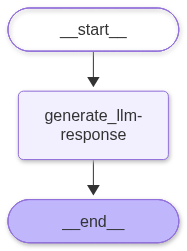

In [5]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())